In [1]:
import pandas as pd 
import numpy as np 
from sklearn.model_selection import train_test_split, cross_validate 
from sklearn.compose import ColumnTransformer 
from sklearn.pipeline import Pipeline 
from sklearn.impute import SimpleImputer 
from sklearn.preprocessing import StandardScaler, OneHotEncoder 
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier 
df = pd.read_csv(
    "../data/processed/processed_data.csv"
) 
X = df.drop("disease", axis=1) 
y = df["disease"]   
numeric_features = X.select_dtypes(
    include=["int64", "float64"] 
).columns.tolist() 
categorical_features = X.select_dtypes(
    include=["object", "category"]
).columns.tolist() 
preprocessor = ColumnTransformer([
    (
        "numeric",
        Pipeline([
            ("imputer", SimpleImputer(strategy="median")),
            ("scaler", StandardScaler())
        ]),
        numeric_features
    ),
    (
        "categorical",
        Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("encoder", OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ))
        ]),
        categorical_features
    )
]) 

In [2]:
models = {
    "Logistic Regression": LogisticRegression(
        max_iter=2000
    ), 
    "Decision Tree": DecisionTreeClassifier(
         random_state=42
    ), 
    "Random Forest": RandomForestClassifier(
         n_estimators=200,
         random_state=42  
    ),  
    "KNN": KNeighborsClassifier(
        n_neighbors=7 
    ), 
    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )  
} 

In [3]:
# Cross-validation 
results = [] 
for name, model in models.items():
    pipeline = Pipeline([
        ("preprocessor", preprocessor),
        ("model", model) 
    ]) 
    scores = cross_validate(
        pipeline,
        X,
        y,
        cv=5,
        scoring=[
            "accuracy",
            "precision_macro",
            "recall_macro",
            "f1_macro"
        ],
        n_jobs=-1
    ) 
    results.append({
        "Model": name,
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision_macro"].mean(),
        "Recall": scores["test_recall_macro"].mean(),
        "F1": scores["test_f1_macro"].mean()
    })  
results_df = pd.DataFrame(results) 
results_df = results_df.sort_values(
    "F1",
    ascending=False
) 
results_df 

,Model,Accuracy,Precision,Recall,F1
0,Logistic Regression,0.395333,0.386172,0.384758,0.372603
4,Gradient Boosting,0.360667,0.358254,0.354480,0.351086
2,Random Forest,0.364667,0.354092,0.355810,0.344224
3,KNN,0.346667,0.344591,0.342040,0.337696
1,Decision Tree,0.298667,0.298318,0.294986,0.295000


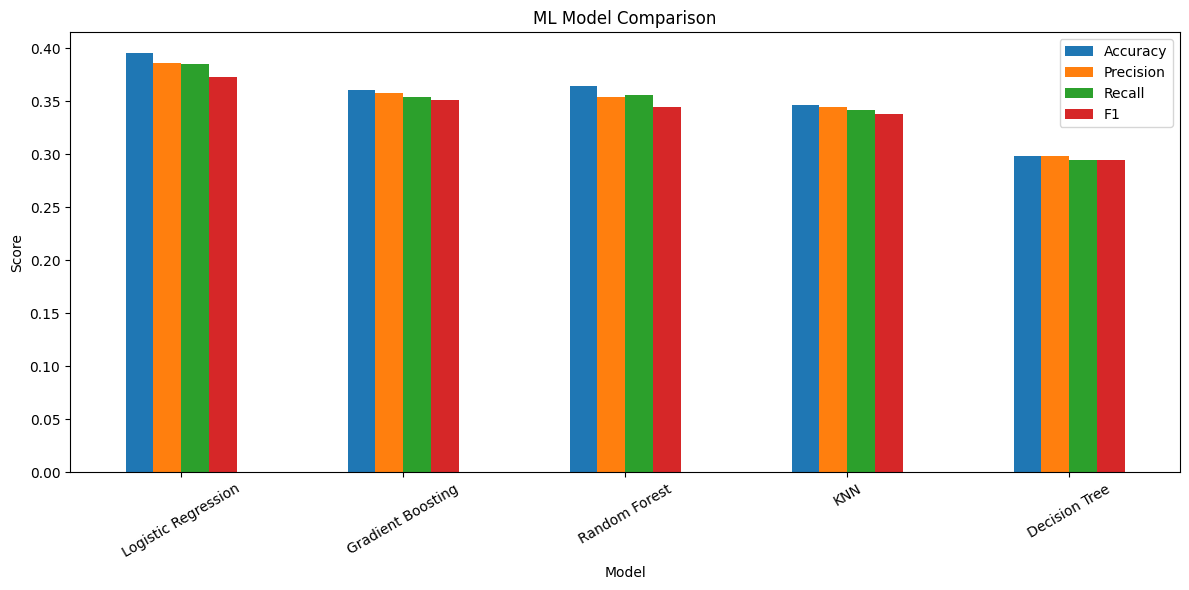

In [4]:
# model comparison chart 
import matplotlib.pyplot as plt 
results_df.set_index("Model")[
    ["Accuracy", "Precision", "Recall", "F1"]
].plot(
    kind="bar",
    figsize=(12, 6)
) 
plt.title("ML Model Comparison")
plt.ylabel("Score")
plt.xticks(rotation=30)
plt.tight_layout() 
plt.savefig(
    "../reports/model_comparison.png"
) 
plt.show()  